In [152]:
import glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Assignment 3: Data Cleaning aur Preprocessing
## 1. Dataset Description
- **Title:** Stroke Prediction Dataset
- **Source:** Kaggle (fedesoriano) - https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset
- **Size:** 5110 rows, 12 columns
- **Main features:** age, gender, hypertension, heart_disease, ever_married, work_type, residence_type, avg_glucose_level, bmi, smoking_status
- **Target:** stroke (1 = stroke aaya, 0 = nahi aaya)
- **Objective:** Patient ki health aur lifestyle information se stroke ka risk predict karna.

In [153]:
files = glob.glob('/kaggle/input/**/healthcare-dataset-stroke-data.csv', recursive=True)
df = pd.read_csv(files[0])

print("Rows, Columns:", df.shape)
print(df.columns.tolist())
print("\nData types:\n", df.dtypes)
df.info()
display(df.head())
display(df.describe().T.round(2))

Rows, Columns: (5110, 12)
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']

Data types:
 id                     int64
gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
Residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.83,21161.72,67.00,17741.25,36932.00,54682.00,72940.00
age,5110.0,43.23,22.61,0.08,25.00,45.00,61.00,82.00
hypertension,5110.0,0.10,0.30,0.00,0.00,0.00,0.00,1.00
heart_disease,5110.0,0.05,0.23,0.00,0.00,0.00,0.00,1.00
avg_glucose_level,5110.0,106.15,45.28,55.12,77.24,91.88,114.09,271.74
bmi,4909.0,28.89,7.85,10.30,23.50,28.10,33.10,97.60
stroke,5110.0,0.05,0.22,0.00,0.00,0.00,0.00,1.00


bmi    201
dtype: int64
BMI missing: 3.93%
bmi
bmi present    0.042575
bmi missing    0.199005
Name: stroke, dtype: float64


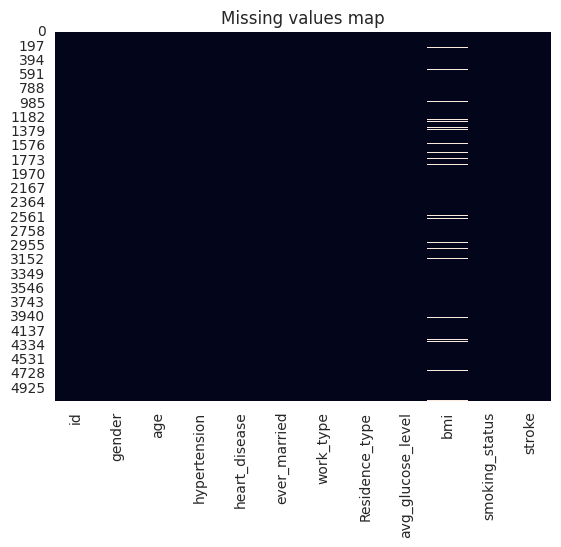

In [154]:
missing = df.isnull().sum()
print(missing[missing > 0])
print(f"BMI missing: {df['bmi'].isnull().mean()*100:.2f}%")

# Kya missing hona khud koi information deta hai?
print(df.groupby(df['bmi'].isnull())['stroke'].mean().rename({False:'bmi present', True:'bmi missing'}))

sns.heatmap(df.isnull(), cbar=False); plt.title("Missing values map"); plt.show()

**Problem:** bmi mein 201 values missing hain (~3.9%).
**Method:** Median imputation, lekin train/test split ke BAAD (pipeline mein, Section 14).
**Why:** BMI right-skewed hai aur outliers hain, to mean bigar jata hai, median safe hai. Split se pehle imputation karte to test data ki information train mein aa jati (data leakage). Saath mein `bmi_missing` flag banayenge, kyunke missing wale patients mein stroke rate ~19.9% hai jabke present walon mein ~4.3%.
**Result:** (pipeline run hone ke baad likho: missing values 0 ho gayi.)

In [155]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate ids:", df['id'].duplicated().sum())
print("Duplicates (id ke baghair):", df.drop(columns='id').duplicated().sum())

df = df.drop_duplicates()
df = df.drop(columns='id')    # id sirf identifier hai
print("Shape ab:", df.shape)

Duplicate rows: 0
Duplicate ids: 0
Duplicates (id ke baghair): 0
Shape ab: (5110, 11)


**Problem:** duplicate rows ho sakti hain jo model ko ek hi patient do baar dikha dein.
**Method:** rows, ids aur id ke baghair rows, teeno tareeqon se duplicates check kiye. `drop_duplicates()` lagaya, phir `id` column drop kiya.
**Why:** `id` sirf identifier hai, is se stroke predict nahi hota, aur model ise ghalti se pattern samajh sakta hai.
**Result:** (apna output likho: kitne duplicates mile? mere dataset mein 0 the.)

In [156]:
print("--- Pehle ---")
for c in df.select_dtypes('object').columns:
    print(c, "->", df[c].unique())

# Column names aur text ko consistent banao
df.columns = df.columns.str.lower()            # Residence_type -> residence_type
for c in df.select_dtypes('object').columns:
    df[c] = df[c].str.strip().str.lower()

print("\n--- Baad mein ---")
for c in df.select_dtypes('object').columns:
    print(c, "->", df[c].unique())

--- Pehle ---
gender -> ['Male' 'Female' 'Other']
ever_married -> ['Yes' 'No']
work_type -> ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
Residence_type -> ['Urban' 'Rural']
smoking_status -> ['formerly smoked' 'never smoked' 'smokes' 'Unknown']

--- Baad mein ---
gender -> ['male' 'female' 'other']
ever_married -> ['yes' 'no']
work_type -> ['private' 'self-employed' 'govt_job' 'children' 'never_worked']
residence_type -> ['urban' 'rural']
smoking_status -> ['formerly smoked' 'never smoked' 'smokes' 'unknown']


**Problem:** column names aur text values mein mixed case hai (`Residence_type`, `Private`, `Govt_job`), jo baad mein encoding mein masla kar sakta hai.
**Method:** sab column names aur text values ko lowercase kiya aur extra spaces strip kiye.
**Why:** consistent format se encoding aur groupby mein galti nahi hoti.
**Result:** sab categories ab lowercase mein hain.

In [157]:
print(df['gender'].value_counts())

# 'other' sirf 1 row hai, model us se kuch seekh nahi sakta
df = df[df['gender'] != 'other']
print("Shape ab:", df.shape)

gender
female    2994
male      2115
other        1
Name: count, dtype: int64
Shape ab: (5109, 11)


**Problem:** `gender` mein 'other' sirf 1 row mein hai.
**Method:** wo row hata di.
**Why:** 1 row se model kuch seekh nahi sakta, aur train/test split mein stratify ya encoding mein masla bhi kar sakti hai.
**Result:** `gender` ab sirf male aur female hai (5109 rows).

In [158]:
print("Age < 18 aur married:", ((df['age'] < 18) & (df['ever_married'] == 'yes')).sum())
print("Age < 1 saal:", (df['age'] < 1).sum())
print("\nwork_type = children ki age:")
print(df[df['work_type'] == 'children']['age'].describe())
print("\nGlucose range:", df['avg_glucose_level'].min(), "-", df['avg_glucose_level'].max())
print("BMI range:", df['bmi'].min(), "-", df['bmi'].max())
print("smoking_status unknown:", (df['smoking_status'] == 'unknown').sum(),
      f"({(df['smoking_status'] == 'unknown').mean()*100:.1f}%)")
print("\nAge describe:\n", df['age'].describe())

Age < 18 aur married: 0
Age < 1 saal: 43

work_type = children ki age:
count    687.000000
mean       6.841339
std        4.533364
min        0.080000
25%        2.000000
50%        6.000000
75%       11.000000
max       16.000000
Name: age, dtype: float64

Glucose range: 55.12 - 271.74
BMI range: 10.3 - 97.6
smoking_status unknown: 1544 (30.2%)

Age describe:
 count    5109.000000
mean       43.229986
std        22.613575
min         0.080000
25%        25.000000
50%        45.000000
75%        61.000000
max        82.000000
Name: age, dtype: float64


**Problem:** kya data mein logically ghalat cheezein hain? (bachchon ki shaadi, impossible age, impossible values)
**Method:** age vs ever_married, age vs work_type, aur age/glucose/BMI ki ranges check ki.
**Why:** logically ghalat rows model ko ghalat pattern sikhati hain.
**Result:** (apne output se likho: Age<18 aur married = 0; `children` ki max age 16; 43 infants (age < 1) valid hain; BMI max 97.6 mushkook hai magar remove nahi kiya; ~30% smoking_status 'unknown' hai, ise alag category rakha.)

In [159]:
print(df.dtypes)
for c in ['hypertension', 'heart_disease', 'stroke']:
    print(c, df[c].unique())

# Text columns ko category type do
for c in ['work_type', 'smoking_status']:
    df[c] = df[c].astype('category')
print("\nCategory columns:", df.select_dtypes('category').columns.tolist())

gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object
hypertension [0 1]
heart_disease [1 0]
stroke [1 0]

Category columns: ['work_type', 'smoking_status']


**Problem:** kuch columns ka type model ke liye sahi nahi (text/object).
**Method:** `hypertension`, `heart_disease`, `stroke` pehle se 0/1 integer hain, theek hain. `work_type` aur `smoking_status` ko `category` type diya.
**Why:** sahi dtype se memory kam hoti hai aur encoding saaf rehti hai.
**Result:** numerical, binary aur categorical columns alag alag clear hain.

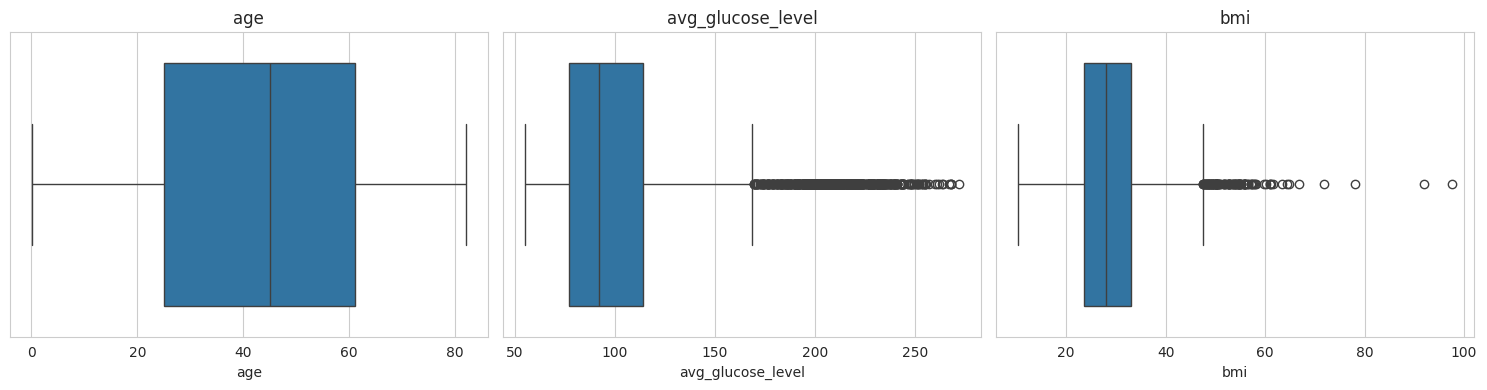

age: IQR bounds = (-29.0, 115.0), outliers = 0
avg_glucose_level: IQR bounds = (22.0, 169.4), outliers = 627
bmi: IQR bounds = (9.1, 47.5), outliers = 110


In [160]:
num_cols = ['age', 'avg_glucose_level', 'bmi']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(x=df[c], ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = ((df[c] < lo) | (df[c] > hi)).sum()
    print(f"{c}: IQR bounds = ({lo:.1f}, {hi:.1f}), outliers = {n}")

**Problem:** `avg_glucose_level` mein ~627 aur `bmi` mein ~110 outliers hain, `age` mein koi nahi.
**Method:** IQR method (Q1 - 1.5*IQR, Q3 + 1.5*IQR). Abhi sirf detect kiya, treat split ke baad karenge (Section 13).
**Why:** ye outliers data error nahi, asli diabetic aur obese mareez ho sakte hain, is liye remove karna sahi nahi. Clip karne se extreme values ka asar kam hota hai magar rows bachti hain.
**Result:** treatment Section 13 mein.

In [161]:
target = 'stroke'
print("Target:", target)
print("Features:", [c for c in df.columns if c != target])

var_types = pd.DataFrame({
    'Type': ['Numerical (continuous)', 'Binary', 'Nominal categorical', 'Ordinal (engineered)', 'Date/Time'],
    'Columns': ['age, avg_glucose_level, bmi',
                'gender, ever_married, residence_type, hypertension, heart_disease',
                'work_type, smoking_status',
                'age_group, glucose_level (neeche banayenge)',
                'Koi nahi (dataset mein date/time column nahi hai)']
})
display(var_types)

Target: stroke
Features: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']


,Type,Columns
0,Numerical (continuous),"age, avg_glucose_level, bmi"
1,Binary,"gender, ever_married, residence_type, hyperten..."
2,Nominal categorical,"work_type, smoking_status"
3,Ordinal (engineered),"age_group, glucose_level (neeche banayenge)"
4,Date/Time,Koi nahi (dataset mein date/time column nahi hai)


In [162]:
df['gender'] = df['gender'].map({'male': 1, 'female': 0})
df['ever_married'] = df['ever_married'].map({'yes': 1, 'no': 0})
df['residence_type'] = df['residence_type'].map({'urban': 1, 'rural': 0})
print(df[['gender', 'ever_married', 'residence_type']].isnull().sum())

gender            0
ever_married      0
residence_type    0
dtype: int64


In [163]:
# 1. BMI missing tha ya nahi (imputation se pehle record karo)
df['bmi_missing'] = df['bmi'].isnull().astype(int)

# 2. Age group (ordinal: 0 = bacha ... 4 = buzurg)
df['age_group'] = pd.cut(df['age'], bins=[0, 18, 40, 60, 75, 121], right=False, labels=False)

# 3. Glucose level (medical thresholds: 0 = normal, 1 = pre-diabetic, 2 = diabetic range)
df['glucose_level'] = pd.cut(df['avg_glucose_level'], bins=[0, 100, 126, 500], right=False, labels=False)

# 4. Total risk factors
df['risk_factors'] = df['hypertension'] + df['heart_disease']

print(df[['bmi_missing', 'age_group', 'glucose_level', 'risk_factors']].describe().T)
print(df.groupby('age_group')['stroke'].mean().round(3))
print(df.groupby('glucose_level')['stroke'].mean().round(3))

                count      mean       std  min  25%  50%  75%  max
bmi_missing    5109.0  0.039342  0.194427  0.0  0.0  0.0  0.0  1.0
age_group      5109.0  1.778626  1.204974  0.0  1.0  2.0  3.0  4.0
glucose_level  5109.0  0.578978  0.792163  0.0  0.0  0.0  1.0  2.0
risk_factors   5109.0  0.151497  0.391956  0.0  0.0  0.0  0.0  2.0
age_group
0    0.002
1    0.005
2    0.038
3    0.092
4    0.197
Name: stroke, dtype: float64
glucose_level
0    0.036
1    0.037
2    0.102
Name: stroke, dtype: float64


**Problem:** raw features se model ko kuch important patterns seedhe nahi milte.
**Method:** 4 naye features: `bmi_missing` (missing hona ek signal hai), `age_group` (5 ordinal groups), `glucose_level` (normal / pre-diabetic / diabetic, medical thresholds 100 aur 126), `risk_factors` (hypertension + heart_disease).
**Why:** stroke rate age_group ke saath 0.2% se 19.7% tak barhta hai aur diabetic glucose range mein ~10% hai, to ye features pattern ko saaf kar dete hain.
**Result:** (apne groupby output se confirm karo ke age_group aur glucose_level ke saath stroke rate barhta hai.)

In [164]:
X = df.drop(columns=target)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_test = X_train.copy(), X_test.copy()

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Stroke % train:", y_train.mean().round(3), "| test:", y_test.mean().round(3))

Train: (4087, 14) | Test: (1022, 14)
Stroke % train: 0.049 | test: 0.049


**Problem:** test data ki information train mein nahi aani chahiye (data leakage).
**Method:** 80/20 split, `stratify=y`, `random_state=42`. Aage ke saare steps (clipping, imputation, scaling) sirf train se seekhe jayenge.
**Why:** target sirf ~4.9% stroke hai, stratify se train aur test dono mein yehi ratio rehta hai.
**Result:** (apne output se likho: train/test shape aur dono mein stroke %.)

In [165]:
for c in ['avg_glucose_level', 'bmi']:
    q1, q3 = X_train[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    X_train[c] = X_train[c].clip(lo, hi)
    X_test[c]  = X_test[c].clip(lo, hi)     # test par bhi TRAIN ke bounds
    print(f"{c}: bounds = ({lo:.1f}, {hi:.1f})")

avg_glucose_level: bounds = (22.6, 168.9)
bmi: bounds = (9.1, 47.5)


**Method:** outliers hataye nahi, IQR bounds par clip kiye (capping/winsorizing). Bounds sirf train se nikale aur test par bhi wohi lagaye.
**Why:** rows kam nahi hoti, extreme values ka asar kam hota hai, aur test ki information leak nahi hoti.

Skewness (pehle):
 age                 -0.14
avg_glucose_level    0.93
bmi                  0.48
dtype: float64


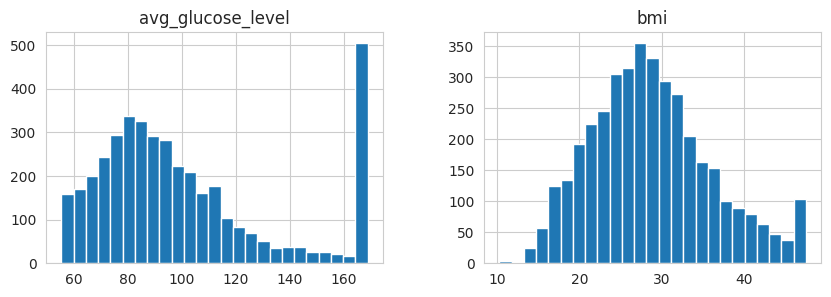

In [166]:
skew_before = X_train[['age', 'avg_glucose_level', 'bmi']].skew().round(2)
print("Skewness (pehle):\n", skew_before)
X_train[['avg_glucose_level', 'bmi']].hist(figsize=(10, 3), bins=25); plt.show()

**Problem:** `avg_glucose_level` (skew ~0.93) right-skewed hai. `age` symmetric hai.
**Method:** skewed columns (glucose, bmi) par `log1p` transform lagayenge. Is se pehle median imputation aur baad mein scaling pipeline ke andar hogi.
**Why:** linear models aur KNN skewed features se kamzor hote hain, log transform distribution ko symmetric ke qareeb laata hai.

In [167]:
skewed_cols  = ['avg_glucose_level', 'bmi']
scale_cols   = ['age', 'risk_factors', 'age_group', 'glucose_level']
binary_cols  = ['gender', 'hypertension', 'heart_disease', 'ever_married',
                'residence_type', 'bmi_missing']
nominal_cols = ['work_type', 'smoking_status']

skew_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),                              # missing BMI
    ('log',    FunctionTransformer(np.log1p, feature_names_out='one-to-one')), # skew kam
    ('scale',  StandardScaler()),                                              # mean 0, std 1
])

preprocessor = ColumnTransformer([
    ('skew',  skew_pipe, skewed_cols),
    ('scale', StandardScaler(), scale_cols),
    ('bin',   'passthrough', binary_cols),
    ('nom',   OneHotEncoder(handle_unknown='ignore', sparse_output=False), nominal_cols),
])

# fit SIRF train par, transform dono par
X_train_p = preprocessor.fit_transform(X_train)
X_test_p  = preprocessor.transform(X_test)

cols = [c.split('__')[-1] for c in preprocessor.get_feature_names_out()]
X_train_p = pd.DataFrame(X_train_p, columns=cols, index=X_train.index)
X_test_p  = pd.DataFrame(X_test_p,  columns=cols, index=X_test.index)

print("Processed shape:", X_train_p.shape, X_test_p.shape)
print("Missing bachi:", X_train_p.isnull().sum().sum(), X_test_p.isnull().sum().sum())
display(X_train_p.head())

Processed shape: (4087, 21) (1022, 21)
Missing bachi: 0 0


,avg_glucose_level,bmi,age,risk_factors,age_group,glucose_level,gender,hypertension,heart_disease,ever_married,...,bmi_missing,work_type_children,work_type_govt_job,work_type_never_worked,work_type_private,work_type_self-employed,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,smoking_status_unknown
845,-1.076969,0.686488,0.209397,-0.387844,0.183977,-0.733761,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3745,-0.436261,-1.072556,-0.629845,-0.387844,-0.646867,-0.733761,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4184,0.709815,-0.770152,-0.364822,-0.387844,-0.646867,0.533193,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3410,0.400872,0.638129,-0.232310,-0.387844,-0.646867,0.533193,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
284,-0.508999,0.502122,-1.292405,-0.387844,-1.477711,-0.733761,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


**Method:** ColumnTransformer: skewed columns (impute, log, scale), numerical/ordinal columns (StandardScaler), binary columns (passthrough), nominal columns (OneHotEncoder).
**Why:** nominal columns ka koi order nahi hota, is liye one-hot. Binary pehle se 0/1 hain. Sab fit sirf train par, taake leakage na ho.
**Result:** (apna output likho: processed shape aur missing values ka count.)

In [168]:
print("Train mean (scaled cols):\n", X_train_p[['age', 'avg_glucose_level', 'bmi']].mean().round(3))
print("Train std:\n", X_train_p[['age', 'avg_glucose_level', 'bmi']].std().round(3))
print("Test mean:\n", X_test_p[['age', 'avg_glucose_level', 'bmi']].mean().round(3))

# Skewness log ke baad
tmp = X_train[['avg_glucose_level', 'bmi']].apply(np.log1p)
print("Skewness log ke baad:\n", tmp.skew().round(2))
print("Skewness pehle:\n", skew_before[['avg_glucose_level', 'bmi']])

Train mean (scaled cols):
 age                 -0.0
avg_glucose_level   -0.0
bmi                 -0.0
dtype: float64
Train std:
 age                  1.0
avg_glucose_level    1.0
bmi                  1.0
dtype: float64
Test mean:
 age                 -0.006
avg_glucose_level   -0.004
bmi                  0.014
dtype: float64
Skewness log ke baad:
 avg_glucose_level    0.45
bmi                 -0.16
dtype: float64
Skewness pehle:
 avg_glucose_level    0.93
bmi                  0.48
dtype: float64


**Verification:** train par mean ~0 aur std ~1 aayi (scaling sahi hui). Test ka mean 0 ke bohot qareeb hai magar bilkul 0 nahi, jo sahi hai kyunke test ko train ke parameters se transform kiya. Skewness log ke baad kam hui (glucose 0.93 se 0.45, bmi 0.48 se -0.16).

In [169]:
df.to_csv('/kaggle/working/stroke_cleaned.csv', index=False)
X_train_p.assign(stroke=y_train.values).to_csv('/kaggle/working/stroke_train_processed.csv', index=False)
X_test_p.assign(stroke=y_test.values).to_csv('/kaggle/working/stroke_test_processed.csv', index=False)
print("Saved!")

Saved!


## Cleaning aur Preprocessing Summary
| Step | Problem | Method | Why | Result |
|---|---|---|---|---|
| Missing values | bmi 201 missing | median (train se), bmi_missing flag | skewed, leakage se bachao | 0 missing |
| Duplicates / id | ... | ... | ... | ... |
| Inconsistent text | ... | lowercase + strip | ... | ... |
| Rare category | gender 'other' 1 row | row remove | ... | ... |
| Logical checks | ... | ... | ... | ... |
| Outliers | glucose 627, bmi 110 | IQR clip (train bounds) | ... | ... |
| Skewness | glucose skewed | log1p | ... | skew kam hui |
| Encoding | ... | binary map + one-hot | ... | ... |
| Scaling | ... | StandardScaler | ... | mean 0, std 1 |
| Feature engineering | ... | 4 naye features | ... | ... |
| Split | ... | 80/20 stratified | ... | ... |

# Exploratory Data Analysis (EDA)
**Case study:** Kaun se health aur lifestyle factors stroke ke risk se juray hain?
**Target:** stroke (Yes / No)
**Flow:** Dataset → Target → Single features → Feature vs Target → Feature vs Feature → Multivariate → Insights

In [170]:
eda = df.copy()
eda['gender']         = eda['gender'].map({1: 'Male', 0: 'Female'})
eda['ever_married']   = eda['ever_married'].map({1: 'Yes', 0: 'No'})
eda['residence_type'] = eda['residence_type'].map({1: 'Urban', 0: 'Rural'})
eda['hypertension']   = eda['hypertension'].map({1: 'Yes', 0: 'No'})
eda['heart_disease']  = eda['heart_disease'].map({1: 'Yes', 0: 'No'})
eda['work_type']      = eda['work_type'].astype(str)
eda['smoking_status'] = eda['smoking_status'].astype(str)
eda['stroke_lbl']     = eda['stroke'].map({0: 'No', 1: 'Yes'})
eda['age_group_lbl']  = eda['age_group'].map({0: '<18', 1: '18-39', 2: '40-59', 3: '60-74', 4: '75+'})
eda['glucose_lbl']    = eda['glucose_level'].map({0: 'Normal', 1: 'Pre-diabetic', 2: 'Diabetic'})

num_cols  = ['age', 'avg_glucose_level', 'bmi']
cat_cols  = ['gender', 'hypertension', 'heart_disease', 'ever_married',
             'work_type', 'residence_type', 'smoking_status']
order_age = ['<18', '18-39', '40-59', '60-74', '75+']
pal       = {'No': '#4c9f70', 'Yes': '#d9534f'}

In [171]:
print("Rows:", eda.shape[0], "| Columns (original features + target):", len(num_cols) + len(cat_cols) + 1)
print("Numerical features :", num_cols)
print("Categorical features:", cat_cols)
print("Target             : stroke (Yes / No)")
display(eda[['gender','age','hypertension','heart_disease','ever_married','work_type',
             'residence_type','avg_glucose_level','bmi','smoking_status','stroke_lbl']].head(6))
display(eda[num_cols].describe().T.round(2))
print("\nMissing values:\n", eda[num_cols + cat_cols].isnull().sum()[lambda s: s > 0])

Rows: 5109 | Columns (original features + target): 11
Numerical features : ['age', 'avg_glucose_level', 'bmi']
Categorical features: ['gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'residence_type', 'smoking_status']
Target             : stroke (Yes / No)


,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke_lbl
0,Male,67.0,No,Yes,Yes,private,Urban,228.69,36.6,formerly smoked,Yes
1,Female,61.0,No,No,Yes,self-employed,Rural,202.21,NaN,never smoked,Yes
2,Male,80.0,No,Yes,Yes,private,Rural,105.92,32.5,never smoked,Yes
3,Female,49.0,No,No,Yes,private,Urban,171.23,34.4,smokes,Yes
4,Female,79.0,Yes,No,Yes,self-employed,Rural,174.12,24.0,never smoked,Yes
5,Male,81.0,No,No,Yes,private,Urban,186.21,29.0,formerly smoked,Yes


,count,mean,std,min,25%,50%,75%,max
age,5109.0,43.23,22.61,0.08,25.00,45.00,61.00,82.00
avg_glucose_level,5109.0,106.14,45.29,55.12,77.24,91.88,114.09,271.74
bmi,4908.0,28.89,7.85,10.30,23.50,28.10,33.10,97.60



Missing values:
 bmi    201
dtype: int64


**Step 1: Understand the Dataset**
- Har row ek patient hai, 5109 patients.
- Numerical features: age, avg_glucose_level, bmi. Categorical: gender, hypertension, heart_disease, ever_married, work_type, residence_type, smoking_status.
- Target `stroke` (Yes / No).
- bmi mein 201 values missing hain (EDA mein ye plots se automatically ignore hoti hain, modeling mein median se bharengi).

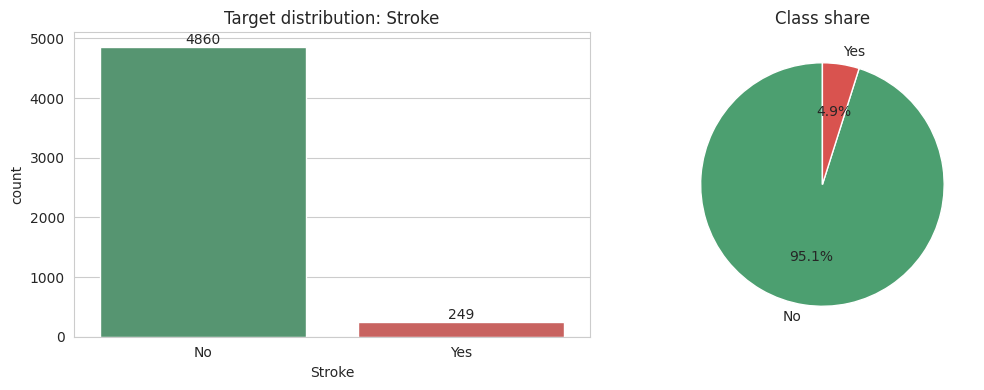

stroke_lbl
No     4860
Yes     249
Imbalance ratio (No:Yes) = 19.5 : 1


In [172]:
counts = eda['stroke_lbl'].value_counts().reindex(['No', 'Yes'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x='stroke_lbl', data=eda, order=['No', 'Yes'], palette=pal, ax=axes[0])
axes[0].set_title('Target distribution: Stroke'); axes[0].set_xlabel('Stroke')
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom')
axes[1].pie(counts, labels=['No', 'Yes'], autopct='%1.1f%%',
            colors=[pal['No'], pal['Yes']], startangle=90)
axes[1].set_title('Class share')
plt.tight_layout(); plt.show()
print(counts.to_string())
print(f"Imbalance ratio (No:Yes) = {counts['No'] / counts['Yes']:.1f} : 1")

**Step 2: Target Variable**
Target bohot imbalanced hai: No = 4860 (95.1%), Yes = 249 (4.9%), ratio ~19.5 : 1.
**Matlab:** model sab ko "no stroke" keh kar bhi ~95% accuracy le sakta hai, is liye sirf accuracy par bharosa nahi. Modeling mein stratified split, class weights, aur Recall / Precision / F1 / ROC-AUC use karenge.

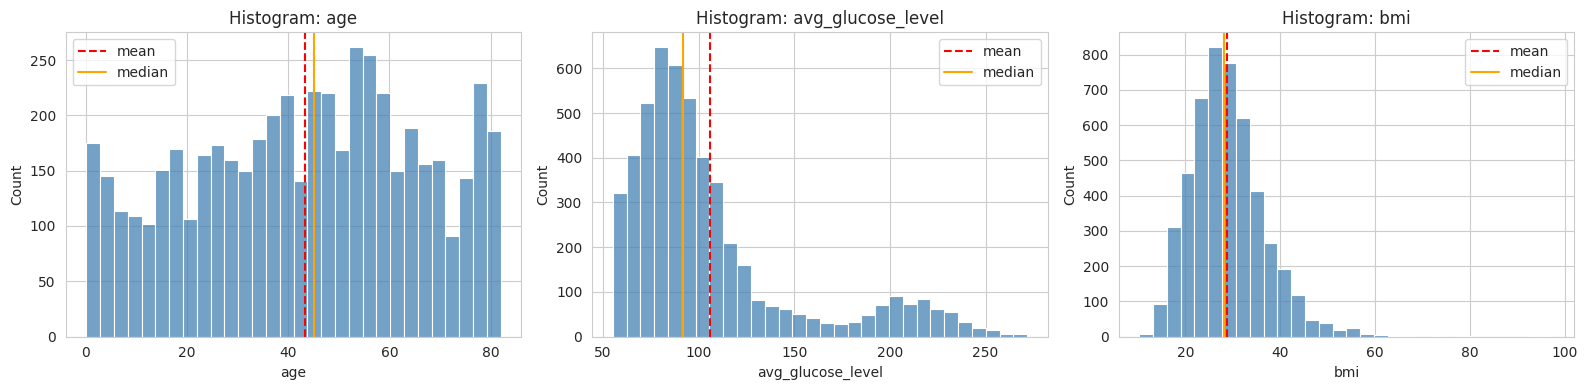

In [173]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, num_cols):
    sns.histplot(eda[c], bins=30, ax=ax, color='steelblue')
    ax.axvline(eda[c].mean(),   color='red',    ls='--', label='mean')
    ax.axvline(eda[c].median(), color='orange', ls='-',  label='median')
    ax.set_title(f'Histogram: {c}'); ax.legend()
plt.tight_layout(); plt.show()

**Step 3: Histogram (shape of each feature)**
- **age:** 0 se 82 tak poori range mein phaili hui, lagbhag symmetric (mean aur median qareeb: ~43 aur 45).
- **avg_glucose_level:** zyada tar patients 55-120 ke beech hain, lekin right tail lambi hai (mean 106 > median 92).
- **bmi:** median ~28 (overweight range), thori si right tail.
- Mean aur median ka farq skewness dikhata hai, isi liye glucose aur bmi par log transform lagaya tha.

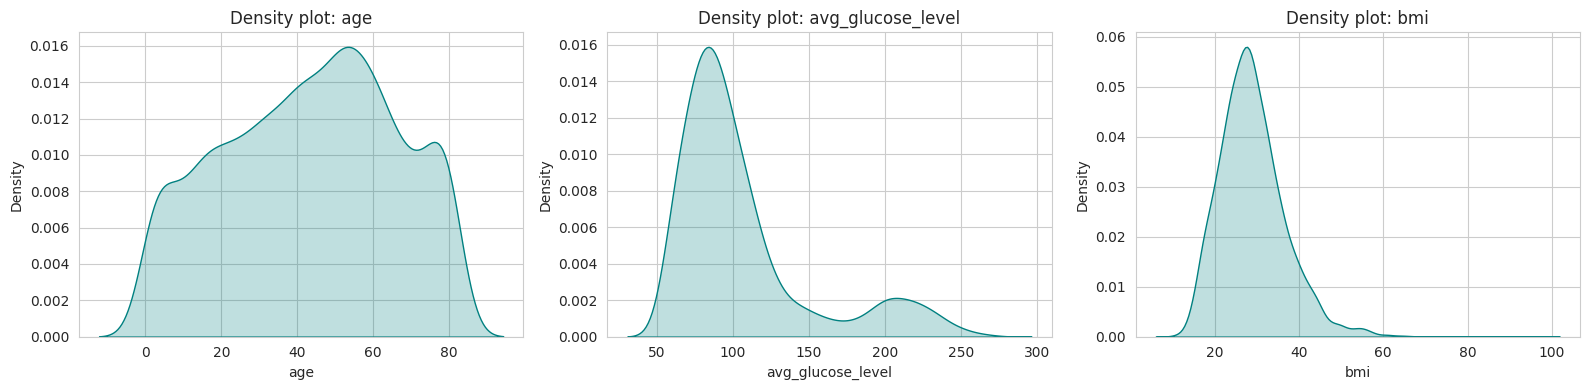

,age,avg_glucose_level,bmi
mean,43.23,106.14,28.89
median,45.00,91.88,28.10
std,22.61,45.29,7.85
skew,-0.14,1.57,1.06


In [174]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, num_cols):
    sns.kdeplot(eda[c].dropna(), fill=True, ax=ax, color='teal')
    ax.set_title(f'Density plot: {c}')
plt.tight_layout(); plt.show()
display(eda[num_cols].agg(['mean', 'median', 'std', 'skew']).round(2))

**Step 4: Density Plot (smooth shape)**
- **avg_glucose_level** mein do peaks hain: ek normal range (~80-100) ke paas aur doosra ~200 ke qareeb (diabetic range). Ye bimodal shape histogram se zyada saaf nazar aati hai.
- **age** mein ek se zyada halka peak hai (bachche aur adult groups), skew ~0 hai.
- **bmi** ek peak aur halki right tail.
- Skewness: glucose 1.57 aur bmi 1.06 (right-skewed), age -0.14 (symmetric).

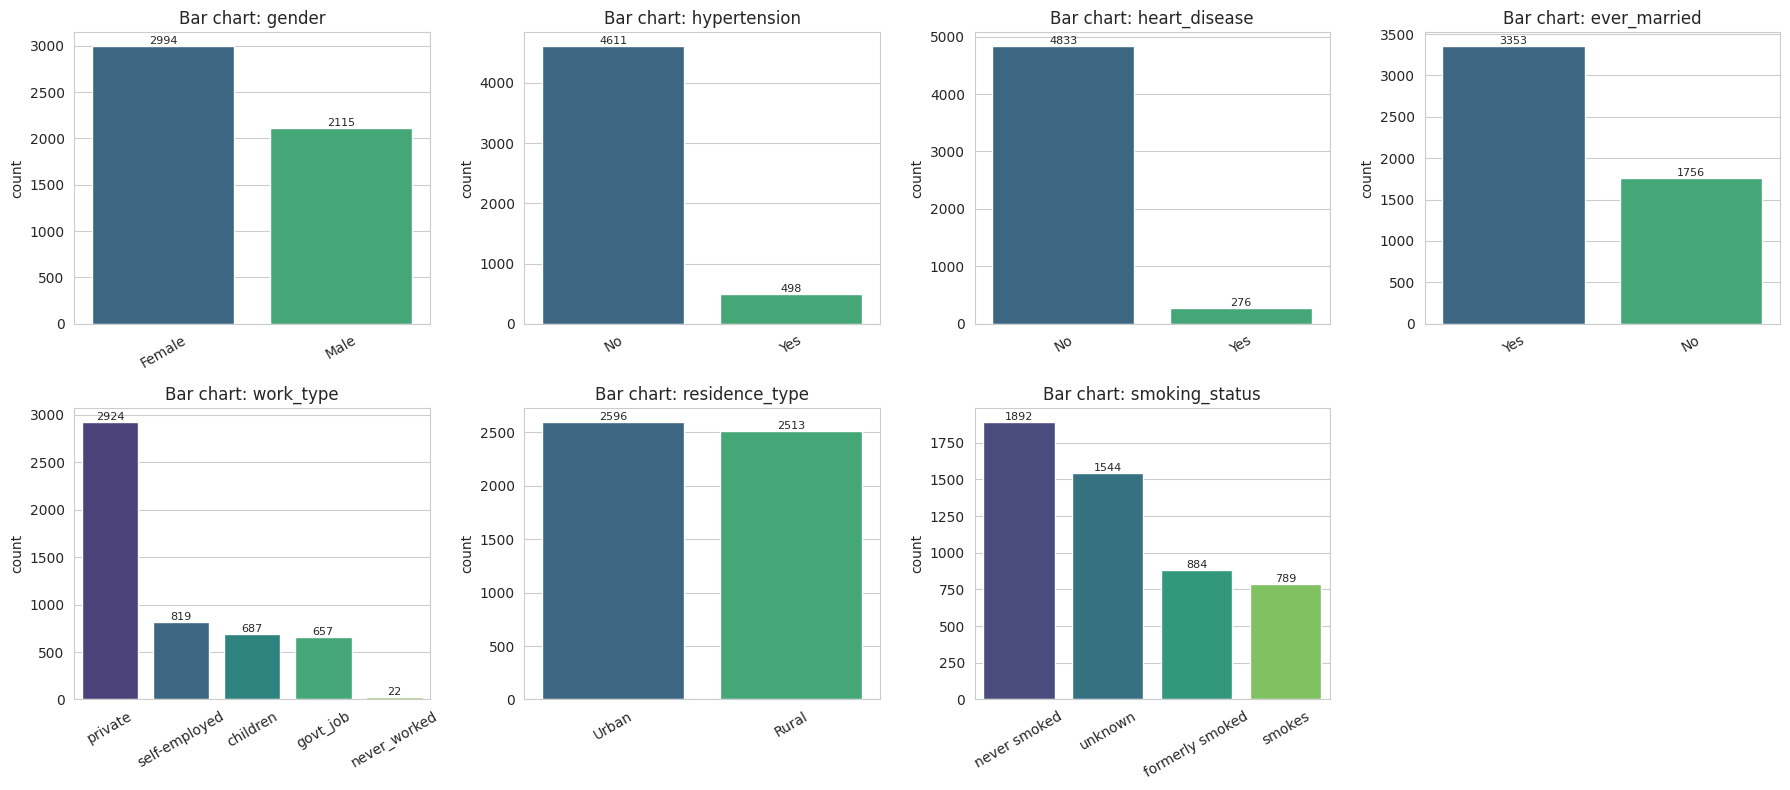

work_type
private          57.2
self-employed    16.0
children         13.4
govt_job         12.9
never_worked      0.4
Name: proportion, dtype: float64 

smoking_status
never smoked       37.0
unknown            30.2
formerly smoked    17.3
smokes             15.4
Name: proportion, dtype: float64 



In [175]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
for ax, c in zip(axes, cat_cols):
    order = eda[c].value_counts().index
    sns.countplot(x=eda[c], order=order, ax=ax, palette='viridis')
    ax.set_title(f'Bar chart: {c}'); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=8)
axes[-1].axis('off')
plt.tight_layout(); plt.show()
for c in ['work_type', 'smoking_status']:
    print((eda[c].value_counts(normalize=True) * 100).round(1), '\n')

**Step 5: Bar Charts (category sizes)**
- **gender:** Female zyada hain (~59%).
- **hypertension / heart_disease:** "No" ka bohot bara hissa, yani positive cases kam hain.
- **work_type:** Private sab se bara (57.2%), Never_worked sab se chhota (0.4%).
- **smoking_status:** never smoked 37%, aur ~30% **unknown** hain, jo ek data quality issue hai.
- **residence_type:** Urban aur Rural lagbhag barabar.

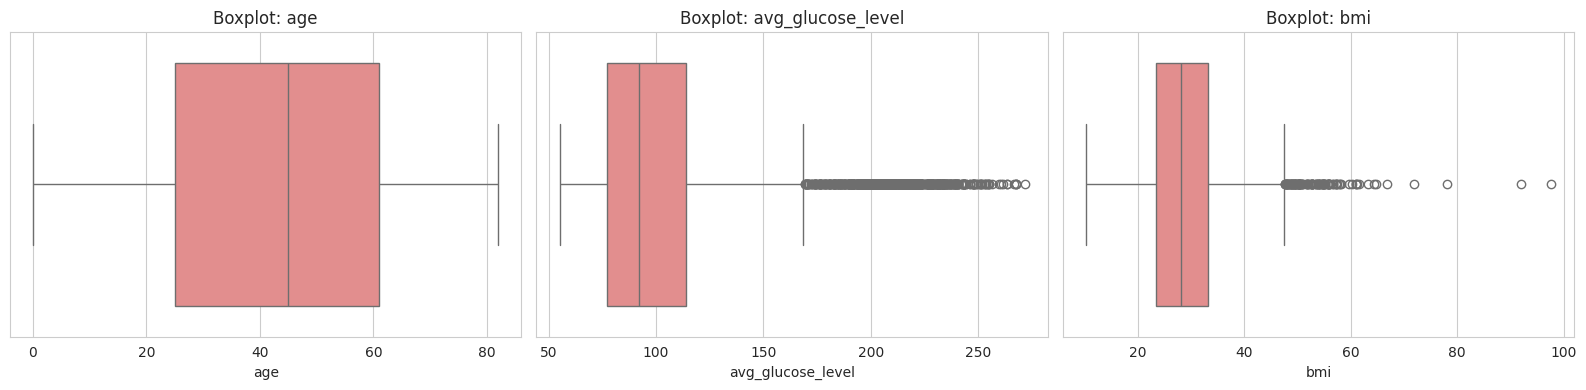

age: Q1=25.0, median=45.0, Q3=61.0, outliers=0
avg_glucose_level: Q1=77.2, median=91.9, Q3=114.1, outliers=627
bmi: Q1=23.5, median=28.1, Q3=33.1, outliers=110


In [176]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(x=eda[c], ax=ax, color='lightcoral')
    ax.set_title(f'Boxplot: {c}')
plt.tight_layout(); plt.show()

for c in num_cols:
    q1, q3 = eda[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = ((eda[c] < lo) | (eda[c] > hi)).sum()
    print(f"{c}: Q1={q1:.1f}, median={eda[c].median():.1f}, Q3={q3:.1f}, outliers={n}")

**Step 6: Boxplot (median, quartiles, outliers)**
- **age:** koi outlier nahi, median ~45, Q1-Q3 = 25 se 61.
- **avg_glucose_level:** ~627 high-side outliers. Ye ghalat data nahi, diabetic mareez hain, isi liye remove nahi kiye balkay train bounds par clip kiye.
- **bmi:** ~110 high outliers, kuch bohot extreme (max 97.6) jo entry error ho sakte hain.

,age,avg_glucose_level,bmi
stroke_lbl,,,
No,41.97,104.79,28.82
Yes,67.73,132.54,30.47


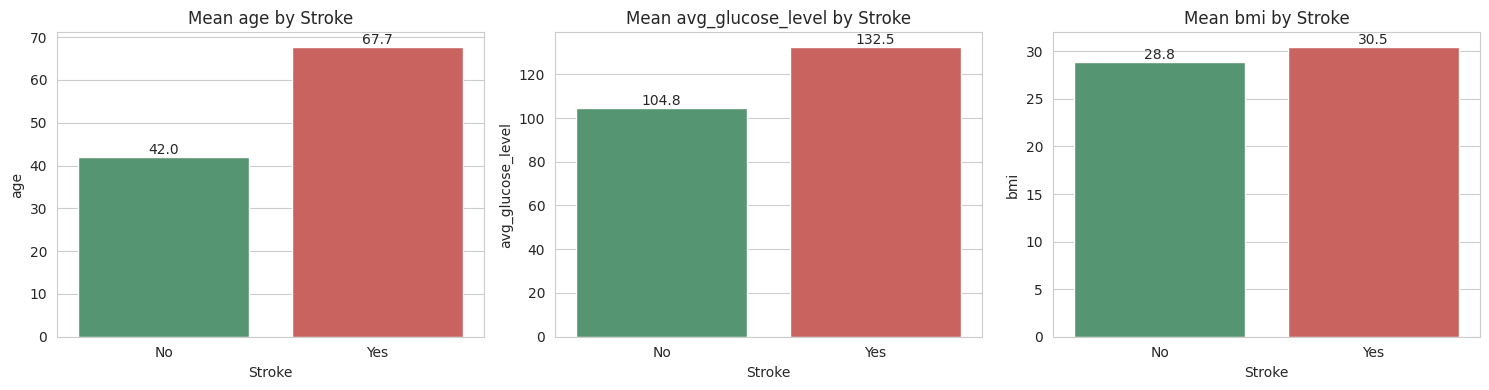

In [177]:
means = eda.groupby('stroke_lbl')[num_cols].mean().round(2)
display(means)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    sns.barplot(x='stroke_lbl', y=c, data=eda, order=['No', 'Yes'], palette=pal, ax=ax, errorbar=None)
    ax.set_title(f'Mean {c} by Stroke'); ax.set_xlabel('Stroke')
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}', (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom')
plt.tight_layout(); plt.show()

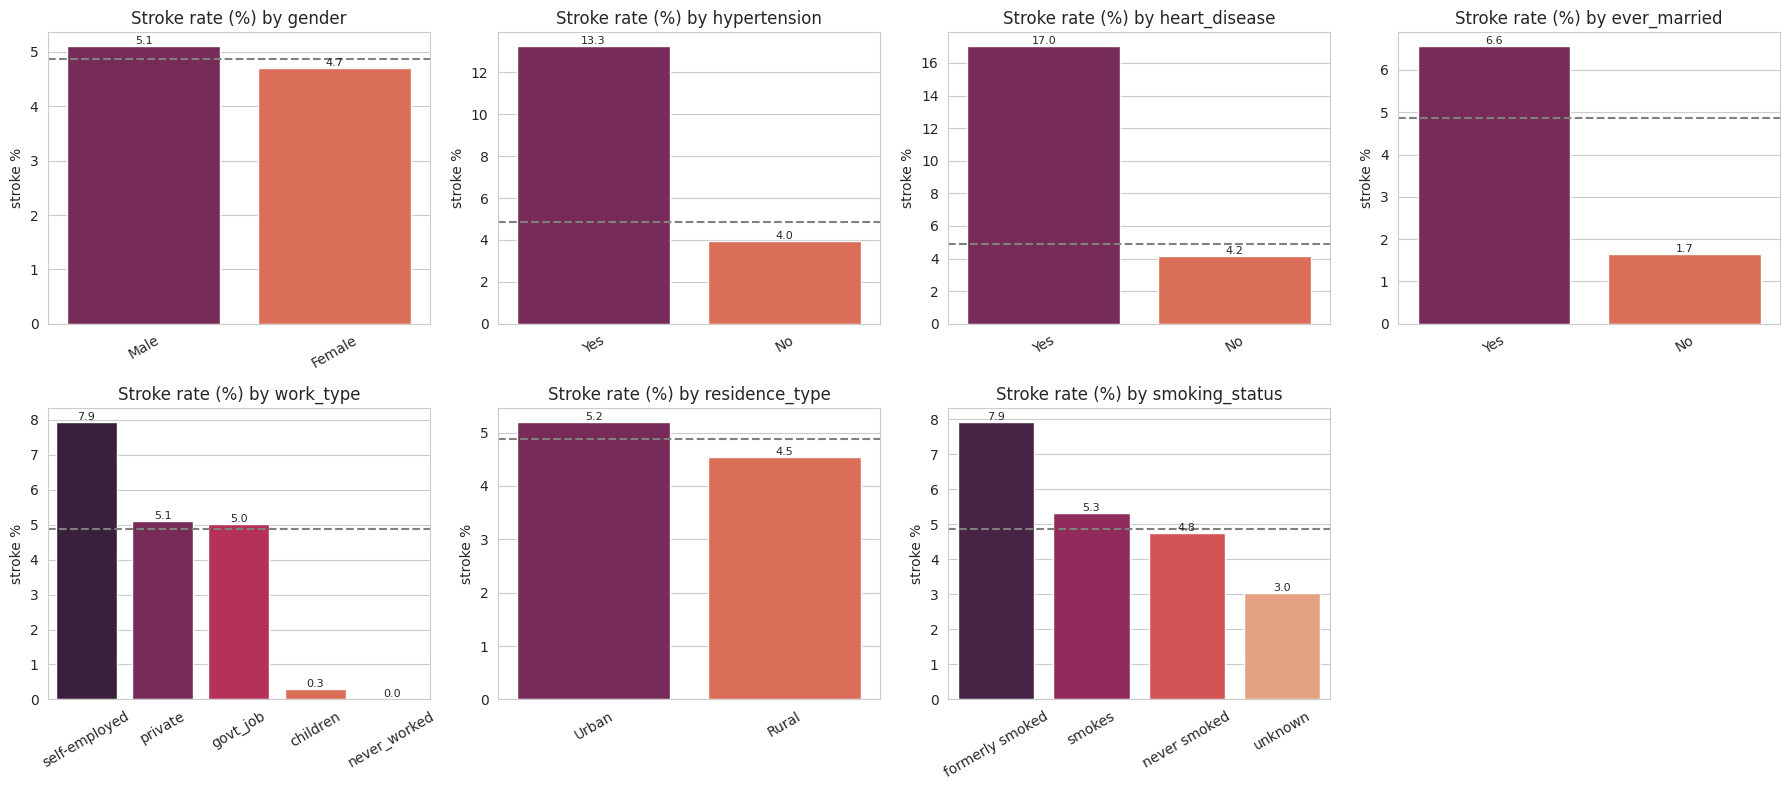

In [178]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
for ax, c in zip(axes, cat_cols):
    rate = eda.groupby(c)['stroke'].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax, palette='rocket')
    ax.axhline(eda['stroke'].mean() * 100, color='gray', ls='--')
    ax.set_title(f'Stroke rate (%) by {c}'); ax.set_xlabel(''); ax.set_ylabel('stroke %')
    ax.tick_params(axis='x', rotation=30)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}', (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=8)
axes[-1].axis('off')
plt.tight_layout(); plt.show()

**Step 7: Feature vs Target**
- **age:** stroke walon ki mean age 67.7 vs 42.0 (bohot bara farq, sab se useful feature).
- **avg_glucose_level:** 132.5 vs 104.8 (stroke walon ka zyada).
- **bmi:** 30.5 vs 28.8 (chhota farq, kamzor feature).
- **Categorical (stroke rate %):** hypertension aur heart_disease "Yes" walon mein rate overall 4.9% se kai guna zyada. `ever_married = Yes` mein bhi zyada, lekin ye age ka asar hai (shaadi shuda log zyada umar ke hain). gender aur residence_type mein farq bohot kam. `work_type = children` mein rate sab se kam. smoking_status mein formerly smoked (7.9%) sab se zyada, `unknown` (3.0%) sab se kam, kyunke unknown mein bohot se bachay hain.

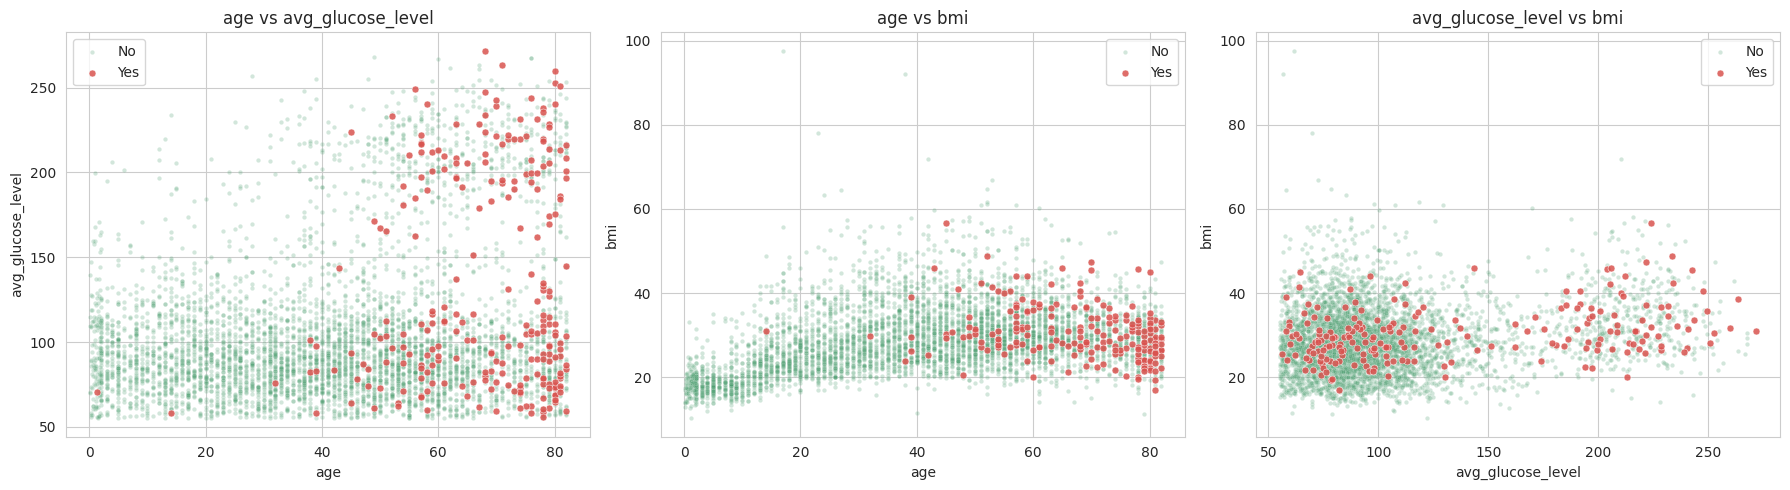

In [179]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pairs = [('age', 'avg_glucose_level'), ('age', 'bmi'), ('avg_glucose_level', 'bmi')]
for ax, (xc, yc) in zip(axes, pairs):
    sns.scatterplot(data=eda[eda['stroke_lbl'] == 'No'],  x=xc, y=yc, color=pal['No'],  alpha=0.25, s=10, ax=ax, label='No')
    sns.scatterplot(data=eda[eda['stroke_lbl'] == 'Yes'], x=xc, y=yc, color=pal['Yes'], alpha=0.85, s=25, ax=ax, label='Yes')
    ax.set_title(f'{xc} vs {yc}')
plt.tight_layout(); plt.show()

**Step 8: Scatter Plots**
- **age vs glucose:** stroke ke (laal) points zyada tar 60 saal se upar hain, aur glucose ke dono clusters (normal aur high) mein milte hain.
- **age vs bmi:** halka sa positive pattern, lekin stroke points poore plot mein bikhre hue hain.
- **glucose vs bmi:** koi saaf pattern nahi.
- Conclusion: age sab se wazeh separator hai, BMI akela koi saaf pattern nahi deta.

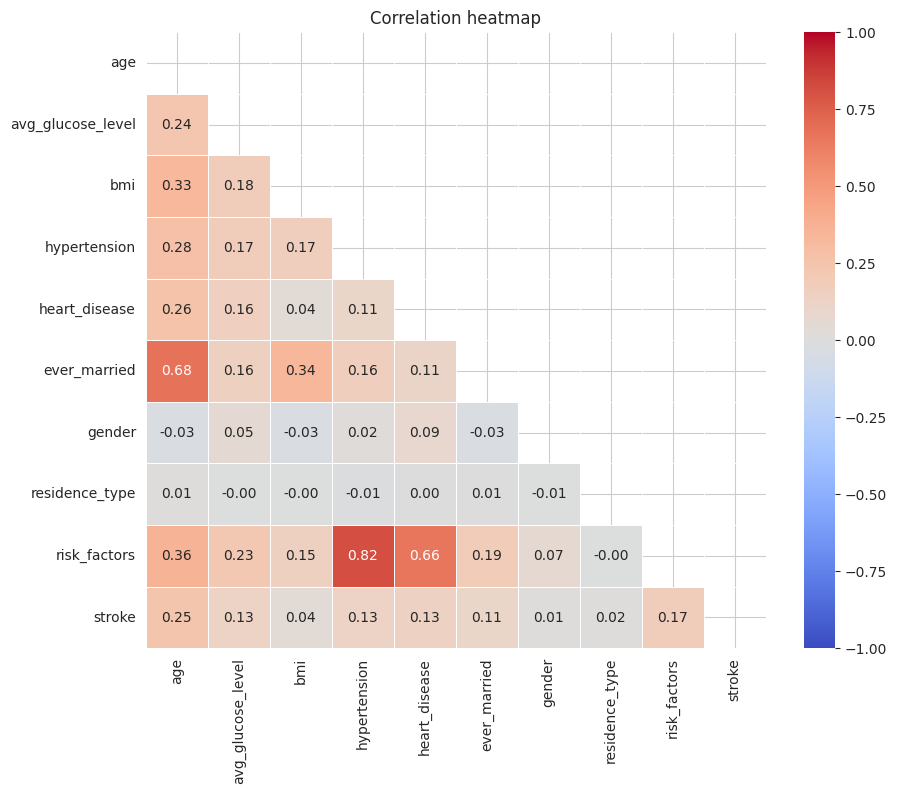

Stroke ke saath correlation:
age                  0.245
risk_factors         0.175
heart_disease        0.135
avg_glucose_level    0.132
hypertension         0.128
ever_married         0.108
bmi                  0.042
residence_type       0.015
gender               0.009

Strong pairs (|r| >= 0.30):


,var1,var2,r
31,risk_factors,hypertension,0.819
10,ever_married,age,0.679
32,risk_factors,heart_disease,0.659
28,risk_factors,age,0.361
12,ever_married,bmi,0.342
1,bmi,age,0.333


In [180]:
corr_cols = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease',
             'ever_married', 'gender', 'residence_type', 'risk_factors', 'stroke']
corr = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation heatmap'); plt.show()

print("Stroke ke saath correlation:")
print(corr['stroke'].drop('stroke').sort_values(ascending=False).round(3).to_string())

pr = corr.where(~mask).stack().reset_index(); pr.columns = ['var1', 'var2', 'r']
print("\nStrong pairs (|r| >= 0.30):")
display(pr[pr['r'].abs() >= 0.30].sort_values('r', key=abs, ascending=False).round(3))

**Step 9: Correlation Heatmap**
- **Stroke ke saath:** sab correlations weak hain. Sab se bara age (0.25), phir risk_factors (0.18), heart_disease (0.14), avg_glucose_level (0.13), hypertension (0.13). bmi (0.04), residence_type, gender lagbhag 0.
- **Strong pairs:** ever_married aur age (0.68), risk_factors apne components se (hypertension 0.82, heart_disease 0.66, ye natural hai kyunke risk_factors unhi ka sum hai). Moderate: age aur bmi (0.33).
- **Strong negative:** koi nahi.
- `age` aur `ever_married` ki high correlation multicollinearity ka khatra hai, khaas kar Logistic Regression mein.
- Note: correlation sirf linear relation naapta hai, low correlation ka matlab "bekaar feature" nahi.

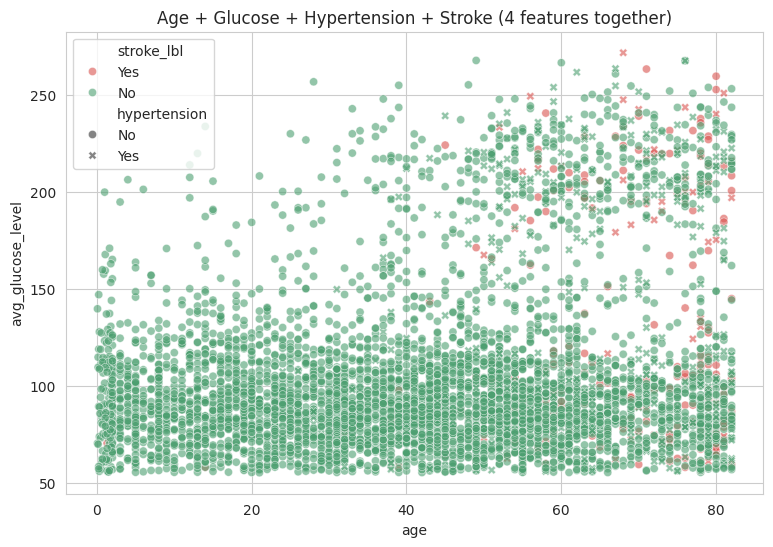

In [181]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=eda, x='age', y='avg_glucose_level', hue='stroke_lbl', style='hypertension',
                palette=pal, alpha=0.6, s=35)
plt.title('Age + Glucose + Hypertension + Stroke (4 features together)')
plt.show()

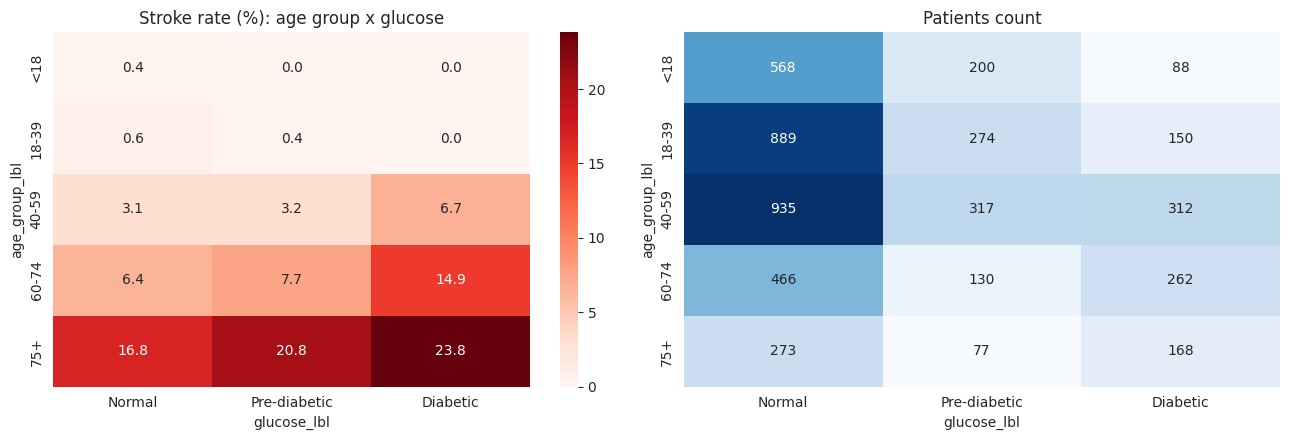

In [182]:
cols_g = ['Normal', 'Pre-diabetic', 'Diabetic']
pv  = eda.pivot_table(index='age_group_lbl', columns='glucose_lbl', values='stroke', aggfunc='mean') * 100
cnt = eda.pivot_table(index='age_group_lbl', columns='glucose_lbl', values='stroke', aggfunc='size')
pv, cnt = pv.reindex(order_age)[cols_g], cnt.reindex(order_age)[cols_g]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(pv, annot=True, fmt='.1f', cmap='Reds', ax=axes[0]); axes[0].set_title('Stroke rate (%): age group x glucose')
sns.heatmap(cnt, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False); axes[1].set_title('Patients count')
plt.tight_layout(); plt.show()

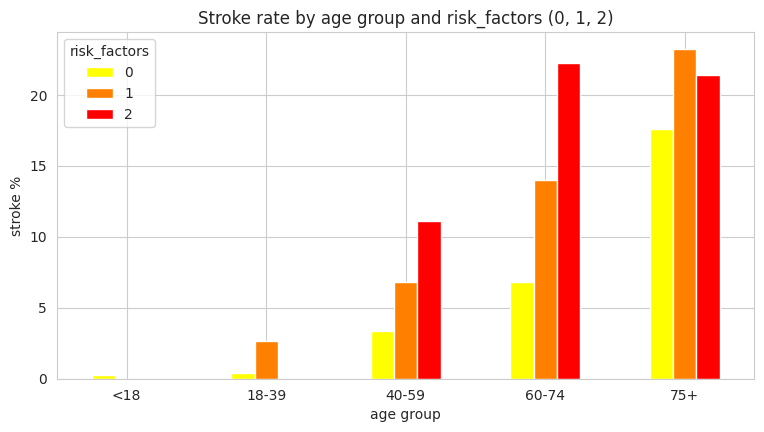

risk_factors,0,1,2
age_group_lbl,,,
<18,0.2,0.0,NaN
18-39,0.4,2.6,NaN
40-59,3.3,6.8,11.1
60-74,6.8,14.0,22.2
75+,17.6,23.3,21.4


In [183]:
pv2 = eda.pivot_table(index='age_group_lbl', columns='risk_factors', values='stroke', aggfunc='mean') * 100
pv2 = pv2.reindex(order_age)
pv2.plot(kind='bar', figsize=(9, 4.5), colormap='autumn_r')
plt.ylabel('stroke %'); plt.xlabel('age group'); plt.xticks(rotation=0)
plt.title('Stroke rate by age group and risk_factors (0, 1, 2)'); plt.legend(title='risk_factors')
plt.show()
display(pv2.round(1))

**Step 10: Multivariate EDA**
- **Age + glucose + hypertension:** stroke ke points buzurg logon mein zyada hain, aur unmein bhi high glucose aur hypertension wale zyada nazar aate hain.
- **Age x glucose heatmap:** buzurg aur diabetic range wale cell mein stroke rate sab se zyada. Naujawan groups mein glucose high hone par bhi rate kam rehta hai, yani **age dominant factor** hai. Kuch cells mein patients bohot kam hain (count heatmap dekho), un ke percentages ehtiyaat se parho.
- **Age x risk_factors:** har age group mein risk_factors 0 se 1 se 2 barhne par rate aam taur par barhta hai (misal: 60-74 mein 6.8% se 14.0% se 22.2%). Chhote cells ki wajah se kuch bars unreliable hain.
- Matlab teeno factors (age, glucose, hypertension/heart disease) mil kar risk barhate hain, akele akele nahi.

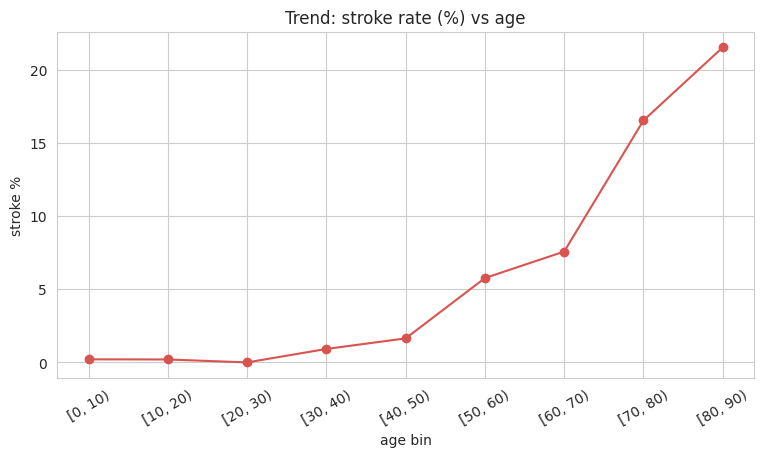

,sum,count,rate_%
age_decade,,,
"[0, 10)",1,472,0.21
"[10, 20)",1,494,0.20
"[20, 30)",0,548,0.00
"[30, 40)",6,655,0.92
"[40, 50)",12,730,1.64
"[50, 60)",48,834,5.76
"[60, 70)",47,621,7.57
"[70, 80)",94,569,16.52
"[80, 90)",40,186,21.51


In [184]:
eda['age_decade'] = pd.cut(eda['age'], bins=list(range(0, 100, 10)), right=False)
trend = eda.groupby('age_decade', observed=True)['stroke'].agg(['sum', 'count', 'mean'])
trend['rate_%'] = (trend['mean'] * 100).round(2)

plt.figure(figsize=(9, 4.5))
plt.plot(trend.index.astype(str), trend['rate_%'], marker='o', color='#d9534f')
plt.title('Trend: stroke rate (%) vs age'); plt.xlabel('age bin'); plt.ylabel('stroke %')
plt.xticks(rotation=30); plt.show()
display(trend[['sum', 'count', 'rate_%']])

In [185]:
print("1) Age < 1 saal:", (eda['age'] < 1).sum(), "| in mein stroke:", eda.loc[eda['age'] < 1, 'stroke'].sum())
print("2) Under-18 mein stroke:", eda.loc[eda['age'] < 18, 'stroke'].sum(), "/", (eda['age'] < 18).sum())
print("3) Glucose > 200:", (eda['avg_glucose_level'] > 200).sum(),
      "| stroke rate: {:.1f}%".format(eda.loc[eda['avg_glucose_level'] > 200, 'stroke'].mean() * 100))
print("4) BMI > 50:", (eda['bmi'] > 50).sum(), "| max BMI:", eda['bmi'].max())
print("5) BMI < 15:", (eda['bmi'] < 15).sum(), "| median age:", eda.loc[eda['bmi'] < 15, 'age'].median())
print("6) smoking_status unknown:", (eda['smoking_status'] == 'unknown').sum(),
      "({:.1f}%)".format((eda['smoking_status'] == 'unknown').mean() * 100))

miss = eda.groupby('bmi_missing')['stroke'].agg(['mean', 'count'])
miss['mean'] = (miss['mean'] * 100).round(1)
miss.index = ['bmi present', 'bmi missing']
display(miss.rename(columns={'mean': 'stroke %'}))

1) Age < 1 saal: 43 | in mein stroke: 0
2) Under-18 mein stroke: 2 / 856
3) Glucose > 200: 434 | stroke rate: 12.9%
4) BMI > 50: 79 | max BMI: 97.6
5) BMI < 15: 42 | median age: 4.5
6) smoking_status unknown: 1544 (30.2%)


,stroke %,count
bmi present,4.3,4908
bmi missing,19.9,201


**Step 11: Trends, Patterns, Anomalies**
- **Trend:** stroke rate age ke saath tez barhta hai: 50 se pehle bohot kam (0 se 1.6%), 50-60 mein 5.8%, 70-80 mein 16.5%, 80+ mein 21.5%.
- **Anomaly 1 (infants):** 43 records ki age 1 saal se kam hai (min 0.08). Valid ho sakte hain, lekin unka BMI aur smoking status mushkook hai.
- **Anomaly 2 (glucose > 200):** 434 patients, stroke rate 12.9%. Data error nahi, diabetic mareez hain.
- **Anomaly 3 (BMI):** 79 patients ka BMI > 50 (max 97.6), aur 42 ka < 15 (median age 4.5, yani bachay, to wo normal hain).
- **Anomaly 4 (missing BMI):** BMI missing walon mein stroke rate 19.9% vs present mein 4.3%. Missing hona khud ek signal hai, is liye `bmi_missing` flag banaya.
- **Anomaly 5:** ~30% smoking_status "unknown", is feature ko kamzor bana sakta hai.

## EDA se Modeling Decisions
1. **Imbalance (4.9%):** accuracy par bharosa nahi, class_weight / stratified split use karenge, aur Recall, Precision, F1, ROC-AUC dekhenge.
2. **Age sab se strong predictor** hai (mean 67.7 vs 42.0, correlation 0.25, rate 0.2% se 19.7%). Model mein zaroor rakhenge.
3. **Hypertension, heart_disease, risk_factors, high glucose** early-warning indicators hain.
4. **bmi, gender, residence_type kamzor** hain, rakh sakte hain lekin bohot asar ki umeed nahi.
5. **ever_married** ka asar asal mein age ka asar hai, linear models mein multicollinearity ka khayal rakhna hoga, tree-based models bhi try karenge.
6. **Missing BMI ek signal hai**, is liye bmi_missing flag rakha aur imputation sirf train se.
7. **Outliers** (glucose, bmi) remove nahi kiye, clip kiye. Skewed columns par log transform.
8. **Data quality:** smoking_status ~30% unknown, BMI mein kuch extreme values.

## EDA Through the 3Cs Lens
- **Character:** graphs ko honestly parha. Weak correlations (max 0.25) ko "strong relationship" nahi bataya, aur EDA se ye claim nahi kiya ke age ya glucose stroke ki *wajah* hain, sirf association dikhaya.
- **Courage:** unusual patterns par sawal uthaye (missing BMI mein 19.9% stroke rate, ever_married ka asar asal mein age ka asar, unknown smoking status).
- **Competence:** har feature ke liye sahi plot chuna (histogram/density shape ke liye, boxplot outliers ke liye, bar chart categories ke liye, scatter/heatmap relationships ke liye) aur har plot ko problem se jorha.

# Assignment 4: Apply and Compare Machine Learning Models

## Task 1: Define the Problem
- **Dataset:** Stroke Prediction Dataset (Kaggle, fedesoriano), 5109 patients (cleaning ke baad).
- **Problem:** Patient ki health aur lifestyle information se predict karna ke usay stroke hoga ya nahi.
- **Features (X):** age, gender, hypertension, heart_disease, ever_married, work_type, residence_type, avg_glucose_level, bmi, smoking_status, aur engineered features (bmi_missing, age_group, glucose_level, risk_factors).
- **Target (y):** `stroke` (1 = stroke, 0 = no stroke).
- **Problem type: CLASSIFICATION**, kyunke target ek category hai (Yes/No), number nahi.
- **Positive class:** Stroke (1).
- **Imbalance:** sirf ~4.9% stroke cases hain, is liye sirf accuracy par bharosa nahi kar sakte.

In [186]:
y_all = pd.concat([y_train, y_test])      # poora target, train + test

print("Features (X):", list(X_train_p.columns))
print("Number of features after preprocessing:", X_train_p.shape[1])
print("\nTarget (y): stroke")
print(y_all.value_counts().rename({0: 'No stroke (0)', 1: 'Stroke (1)'}))
print("\nTarget mein sirf", y_all.nunique(), "categories hain -> Classification problem")

Features (X): ['avg_glucose_level', 'bmi', 'age', 'risk_factors', 'age_group', 'glucose_level', 'gender', 'hypertension', 'heart_disease', 'ever_married', 'residence_type', 'bmi_missing', 'work_type_children', 'work_type_govt_job', 'work_type_never_worked', 'work_type_private', 'work_type_self-employed', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes', 'smoking_status_unknown']
Number of features after preprocessing: 21

Target (y): stroke
stroke
No stroke (0)    4860
Stroke (1)        249
Name: count, dtype: int64

Target mein sirf 2 categories hain -> Classification problem


## Task 2: Train-Test Split
- Data 80% train aur 20% test mein baanta (`train_test_split`, `test_size=0.2`, `stratify=y`, `random_state=42`).
- `stratify=y` se train aur test dono mein stroke ratio (~4.9%) same rehta hai.
- Preprocessing (median imputation, outlier clipping, log, scaling, one-hot) **sirf train se seekhi** aur test par sirf lagayi, taake data leakage na ho.
- Models sirf **train** par train honge aur **unseen test** par evaluate honge.
- Test set ko model ki settings chunne ke liye use nahi kiya. Validation ke liye train par 5-fold cross-validation use hogi.

In [187]:
print("X_train:", X_train_p.shape, "| X_test:", X_test_p.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
print("Train aur test mein common rows:", len(set(X_train_p.index) & set(X_test_p.index)))
print("Stroke % -> train:", round(y_train.mean() * 100, 2), "| test:", round(y_test.mean() * 100, 2))

X_train: (4087, 21) | X_test: (1022, 21)
y_train: (4087,) | y_test: (1022,)
Train aur test mein common rows: 0
Stroke % -> train: 4.87 | test: 4.89


## Task 3: Apply Suitable Models
Classification ke liye 4 models liye, har ek ka sochne ka tareeqa alag hai:

| Model | Kaise sochta hai | Is problem mein setting |
|---|---|---|
| Logistic Regression | score, sigmoid, probability, threshold (0.5) | `class_weight='balanced'` |
| KNN | sab se qareeb K mareezon ka vote | K = 15 (class_weight option nahi hota) |
| Decision Tree | sawalon ka rasta (flowchart) | `max_depth=5` (overfitting rokne ke liye), `class_weight='balanced'` |
| Random Forest | bohot se trees ka vote | 300 trees, `max_depth=8`, `min_samples_leaf=5`, `class_weight='balanced'` |

`class_weight='balanced'` minority class (stroke) ko zyada wazan deta hai, kyunke sirf ~4.9% cases hain.

In [188]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve)

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'KNN':                 KNeighborsClassifier(n_neighbors=15),
    'Decision Tree':       DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                                                  class_weight='balanced', random_state=42),
}

lazy_acc = 1 - y_test.mean()
print(f"Lazy model (sab ko 'No stroke' kehna): Accuracy = {lazy_acc:.3f}, Recall = 0.000")

Lazy model (sab ko 'No stroke' kehna): Accuracy = 0.951, Recall = 0.000


In [189]:
def get_metrics(y_true, y_pred, y_prob=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    out = {
        'Accuracy':  accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall':    recall_score(y_true, y_pred),
        'F1-Score':  f1_score(y_true, y_pred),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    }
    if y_prob is not None:
        out['ROC-AUC'] = roc_auc_score(y_true, y_prob)
    return out

test_rows, train_rows, preds, probas = {}, {}, {}, {}
for name, model in models.items():
    model.fit(X_train_p, y_train)                       # sirf train par seekha
    preds[name]  = model.predict(X_test_p)              # unseen test par predict
    probas[name] = model.predict_proba(X_test_p)[:, 1]
    test_rows[name]  = get_metrics(y_test, preds[name], probas[name])
    train_rows[name] = get_metrics(y_train, model.predict(X_train_p))   # overfitting check ke liye

res       = pd.DataFrame(test_rows).T
res_train = pd.DataFrame(train_rows).T
for c in ['TN', 'FP', 'FN', 'TP']:
    res[c] = res[c].astype(int)
res.index.name = 'Model'
print("Training complete")

Training complete


## Task 4: Evaluate the Models
"Stroke" ko **positive class** liya.
- **Confusion Matrix:** TP (stroke pakra), TN (sahi no stroke), FP (false alarm), FN (stroke miss hua).
- **Accuracy:** (TP+TN)/Total, kul kitne sahi. Imbalance mein gumrah kar sakti hai.
- **Precision:** TP/(TP+FP), jab model "stroke" kahe to kitni baar sahi.
- **Recall:** TP/(TP+FN), asal stroke mareezon mein se kitne pakre.
- **F1:** Precision aur Recall ka balance.
- **ROC-AUC (extra):** threshold se azaad, class 1 ko class 0 se alag karne ki salahiyat.
- **Sab se khatarnak ghalti:** FN, yani stroke wala mareez miss ho jaye aur use koi madad na mile.

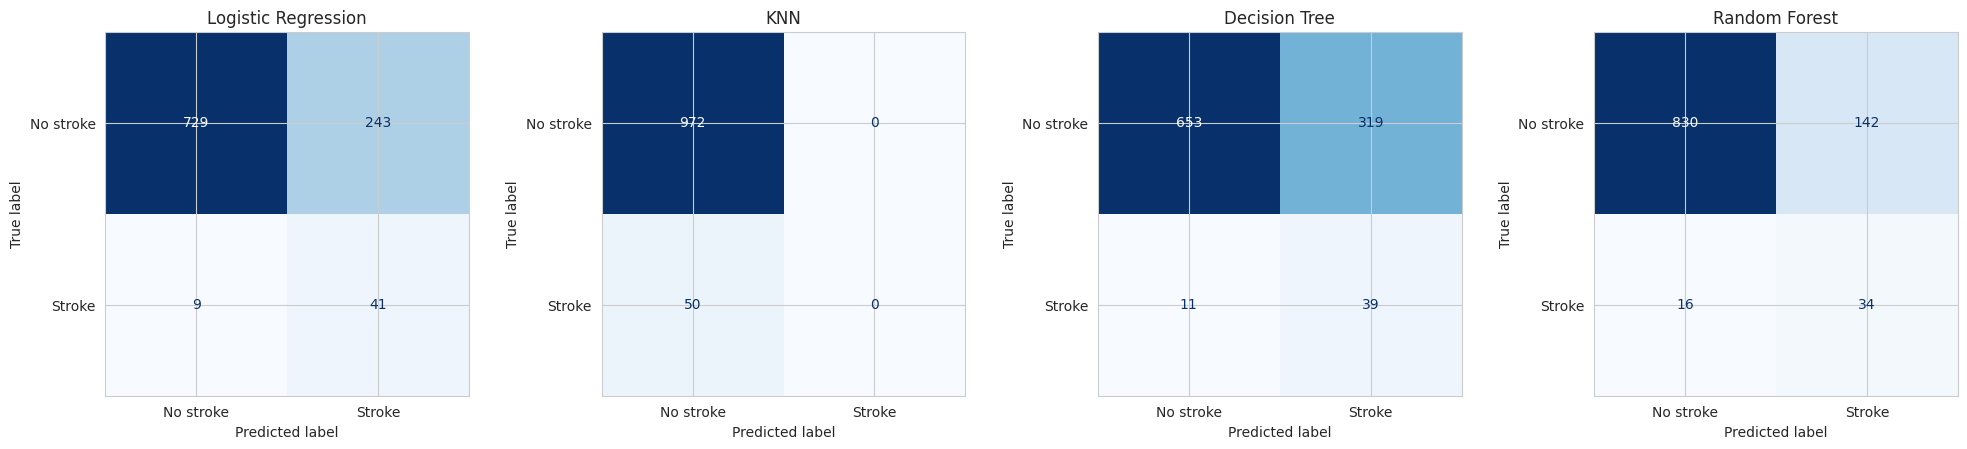

,TN,FP,FN,TP
Model,,,,
Logistic Regression,729,243,9,41
KNN,972,0,50,0
Decision Tree,653,319,11,39
Random Forest,830,142,16,34


In [190]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[name]),
                           display_labels=['No stroke', 'Stroke']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()
display(res[['TN', 'FP', 'FN', 'TP']])

**Confusion Matrix Interpretation**
- **Logistic Regression:** TP = 41, FN = 9 (sab se kam miss), lekin FP = 243 (zyada false alarms).
- **Decision Tree:** TP = 39, FN = 11, FP = 319 (sab se zyada false alarms).
- **Random Forest:** TP = 34, FN = 16, FP = 142 (alarms kam, lekin zyada strokes miss).
- **KNN:** TP = 0, FN = 50. Isne ek bhi stroke nahi pakra, FP = 0 sirf is liye kyunke usne kisi ko "stroke" kaha hi nahi.
(Ye mere purane run ke numbers hain, apne output se milao.)

In [191]:
for name in models:
    print("=" * 55, "\n", name, "\n", "=" * 55)
    print(classification_report(y_test, preds[name], target_names=['No stroke', 'Stroke'], zero_division=0))

 Logistic Regression 
              precision    recall  f1-score   support

   No stroke       0.99      0.75      0.85       972
      Stroke       0.14      0.82      0.25        50

    accuracy                           0.75      1022
   macro avg       0.57      0.78      0.55      1022
weighted avg       0.95      0.75      0.82      1022

 KNN 
              precision    recall  f1-score   support

   No stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

 Decision Tree 
              precision    recall  f1-score   support

   No stroke       0.98      0.67      0.80       972
      Stroke       0.11      0.78      0.19        50

    accuracy                           0.68      1022
   macro avg       0.55      0.73      0.49      1022
weighted avg       0.94      0

## Task 5: Compare the Models

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.753,0.144,0.82,0.246
KNN,0.951,0.000,0.00,0.000
Decision Tree,0.677,0.109,0.78,0.191
Random Forest,0.845,0.193,0.68,0.301


,ROC-AUC
Model,
Logistic Regression,0.842
KNN,0.717
Decision Tree,0.790
Random Forest,0.835


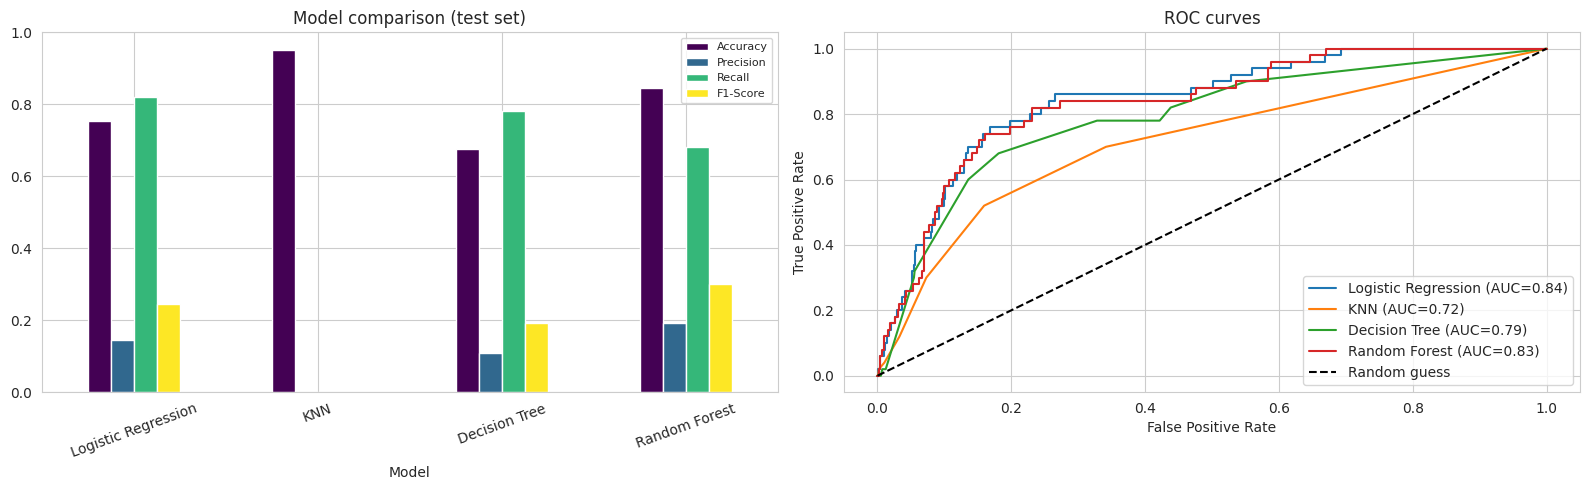

In [192]:
comparison = res[['Accuracy', 'Precision', 'Recall', 'F1-Score']].round(3)
display(comparison)
display(res[['ROC-AUC']].round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
comparison.plot(kind='bar', ax=axes[0], colormap='viridis')
axes[0].set_title('Model comparison (test set)'); axes[0].set_ylim(0, 1)
axes[0].tick_params(axis='x', rotation=20); axes[0].legend(loc='upper right', fontsize=8)

for name in models:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={res.loc[name, 'ROC-AUC']:.2f})")
axes[1].plot([0, 1], [0, 1], 'k--', label='Random guess')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC curves'); axes[1].legend()
plt.tight_layout(); plt.show()

In [193]:
gap = pd.DataFrame({
    'Train Recall': res_train['Recall'], 'Test Recall': res['Recall'],
    'Recall gap':   res_train['Recall'] - res['Recall'],
    'Train F1':     res_train['F1-Score'], 'Test F1': res['F1-Score'],
    'F1 gap':       res_train['F1-Score'] - res['F1-Score'],
}).round(3)
display(gap)

,Train Recall,Test Recall,Recall gap,Train F1,Test F1,F1 gap
Logistic Regression,0.839,0.82,0.019,0.246,0.246,0.001
KNN,0.000,0.00,0.000,0.000,0.000,0.000
Decision Tree,0.950,0.78,0.170,0.224,0.191,0.032
Random Forest,0.894,0.68,0.214,0.392,0.301,0.091


**Overfitting / Underfitting kaise parhein:**
| Pattern | Train | Test | Matlab |
|---|---|---|---|
| Underfitting | Weak | Weak | Model bohot simple |
| Good fit | Good | Good | Generalize karta hai |
| Overfitting | Bohot strong | Bohot kamzor | Training ki details yaad kar li |

(Apni `gap` table dekh kar likho: kis model mein Train aur Test ka farq sab se bara hai (overfitting ka shak)? Kis model ka Train aur Test dono Recall kamzor hain (underfitting)? KNN ka train Recall bhi 0 hai to wo overfit nahi, balkay minority class ko seekh hi nahi paya.)

In [194]:
from sklearn.model_selection import StratifiedKFold, cross_validate
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = {}
for name, model in models.items():
    s = cross_validate(model, X_train_p, y_train, cv=skf, scoring=['recall', 'f1'])
    cv_rows[name] = {'CV Recall mean': s['test_recall'].mean(), 'CV Recall std': s['test_recall'].std(),
                     'CV F1 mean':     s['test_f1'].mean(),     'CV F1 std':     s['test_f1'].std()}
cv_df = pd.DataFrame(cv_rows).T.round(3)
display(cv_df)

,CV Recall mean,CV Recall std,CV F1 mean,CV F1 std
Logistic Regression,0.814,0.043,0.239,0.016
KNN,0.000,0.000,0.000,0.000
Decision Tree,0.774,0.041,0.218,0.022
Random Forest,0.558,0.047,0.261,0.024


**Cross-validation:** train data ko 5 hisson mein baant kar har model ko 5 baar alag unseen hisse par parkha. Mean batata hai model kitna acha hai, std batata hai kitna stable hai. Agar CV Recall test Recall se bohot milta hai to result bharosemand hai.
(Apne numbers likho: kis model ka CV Recall sab se zyada aur stable hai?)

Sab se zyada Recall    : Logistic Regression  (0.820)
Sab se zyada Precision : Random Forest        (0.193)
Sab se zyada F1-Score  : Random Forest        (0.301)
Sab se zyada ROC-AUC   : Logistic Regression  (0.842)
Sab se zyada Accuracy  : KNN                  (0.951)
Sab se kam FN (missed stroke): Logistic Regression -> 9
Sab se kam FP (false alarm)  : KNN -> 0


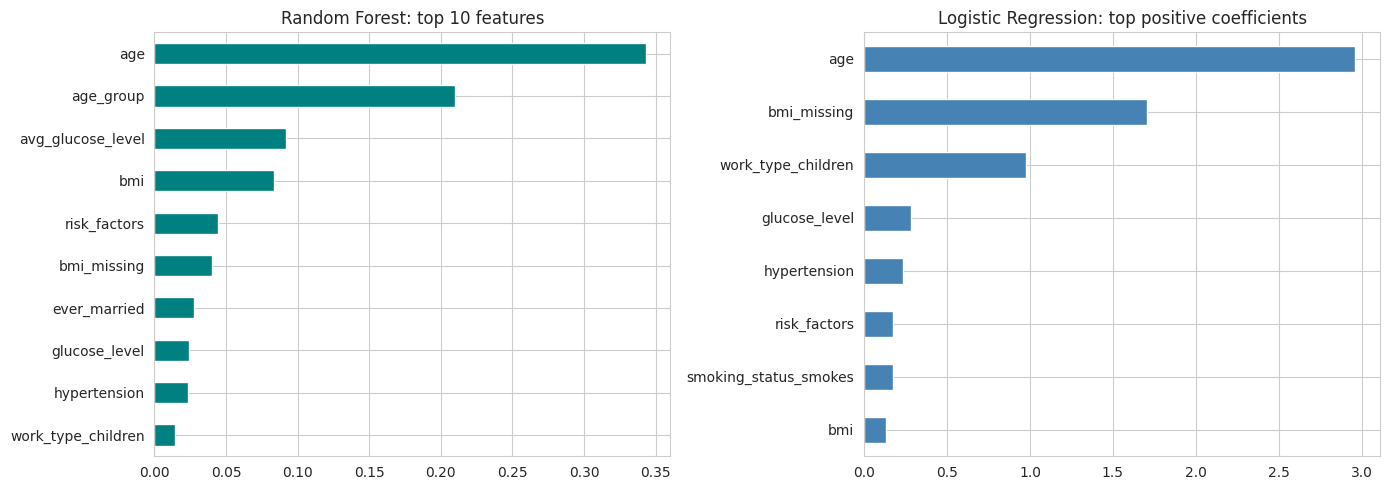

In [195]:
for m in ['Recall', 'Precision', 'F1-Score', 'ROC-AUC', 'Accuracy']:
    print(f"Sab se zyada {m:10s}: {res[m].idxmax():20s} ({res[m].max():.3f})")
print("Sab se kam FN (missed stroke):", res['FN'].idxmin(), "->", res['FN'].min())
print("Sab se kam FP (false alarm)  :", res['FP'].idxmin(), "->", res['FP'].min())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
rf = models['Random Forest']
pd.Series(rf.feature_importances_, index=X_train_p.columns).sort_values().tail(10).plot(
    kind='barh', ax=axes[0], color='teal'); axes[0].set_title('Random Forest: top 10 features')
lr = models['Logistic Regression']
pd.Series(lr.coef_[0], index=X_train_p.columns).sort_values().tail(8).plot(
    kind='barh', ax=axes[1], color='steelblue')
axes[1].set_title('Logistic Regression: top positive coefficients')
plt.tight_layout(); plt.show()

## Final Conclusion

**Test results (unseen test set, 1022 patients, 50 asal stroke cases):**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | FN (miss) | FP (false alarm) |
|---|---|---|---|---|---|---|---|
| Logistic Regression | 0.753 | 0.144 | 0.820 | 0.246 | 0.842 | 9 | 243 |
| KNN | 0.951 | 0.000 | 0.000 | 0.000 | 0.717 | 50 | 0 |
| Decision Tree | 0.677 | 0.109 | 0.780 | 0.191 | 0.790 | 11 | 319 |
| Random Forest | 0.845 | 0.193 | 0.680 | 0.301 | 0.835 | 16 | 142 |

**1. Which model performed best?**
**Logistic Regression.** Isne 50 mein se 41 stroke cases pakre (Recall = 0.82), sab se kam stroke miss kiye (FN = 9), aur sab se zyada ROC-AUC (0.842) hasil kiya. Cross-validation mein bhi iska Recall high aur stable raha (0.814 ± 0.043), yani result sirf is ek test split ka ittefaq nahi hai.

**2. Which metric did I mainly use?**
Mainly **Recall**, saath mein Confusion Matrix (FN count), F1 aur ROC-AUC. Sab se bara number dekh kar faisla nahi kiya. KNN ki Accuracy sab se zyada (0.951) hai, lekin ye "lazy model" (sab ko No stroke kehna, 95.1%) jitni hi hai, aur KNN ka Recall = 0 hai, yani isne ek bhi stroke nahi pakra.

**3. Why is Recall important for this problem?**
Stroke prediction mein sab se khatarnak ghalti False Negative hai: asal stroke wala mareez miss ho jaye aur use koi tawajjo ya extra test na mile. False Positive (false alarm) ka nuqsan kam hai, sirf ek extra check-up. Isi liye Recall ko priority di. Is ki qeemat ye hai ke Precision kam hai (0.144): Logistic Regression ke har 100 "stroke" alerts mein se sirf ~14 asal mein stroke wale hote hain, aur 243 healthy logon ko false alarm milta hai. Ye screening ke liye qabil-e-qubool hai, final diagnosis ke liye nahi.

**4. Overfitting / Underfitting ke signs?**
- **Random Forest:** overfitting/instability ka nishan hai. Iska Test Recall 0.68 hai, lekin Cross-validation Recall sirf 0.558 aur Train Recall bhi isse zyada hai (`gap` table dekho: Train Recall = 0.894 vs Test Recall = 0.68). Yani ye training data ki details kuch zyada seekhta hai aur naye data par stroke cases miss karta hai.
- **Decision Tree:** `max_depth=5` se control kiya, Test Recall 0.78 aur CV Recall 0.774 qareeb hain, to koi bara overfitting nahi, lekin Precision sab se kam (0.109) hai (319 false alarms).
- **Logistic Regression:** Train aur Test performance qareeb hai (CV 0.814 vs Test 0.82), to ye stable aur sahi tarah generalize karta hai. Ye ek simple model hai, is liye overfitting ka khatra kam hai.
- **KNN:** Train aur Test dono Recall 0 hain. Ye overfitting nahi, balkay minority class (stroke) ko seekhne mein nakaami (underfitting for the minority class) hai. K = 15 mein neighbors mein stroke wale itne kam hote hain ke vote hamesha "No stroke" aata hai.

**Why not the other models?**
- **Random Forest** ka F1 (0.301) aur Precision (0.193) sab se behtar hain, aur ye kam false alarms deta hai (142), lekin ye 16 stroke miss karta hai aur CV Recall sirf 0.558 hai. Agar hospital ke paas extra tests ke liye bohot kam wasail hon, to Random Forest ek option ho sakta hai.
- **Decision Tree** Logistic Regression se har metric mein kamzor (Recall 0.78 vs 0.82, FP 319 vs 243, AUC 0.790 vs 0.842).
- **KNN** is imbalanced data par bekaar hai.

**Limitations:**
- Sirf 249 stroke cases hain (test mein 50), is liye numbers split badalne par thore badal sakte hain.
- Precision sab models mein kam hai, kyunke stroke bohot rare hai (~4.9%).
- Threshold tuning, SMOTE aur hyperparameter tuning try nahi kiye. In se Precision aur Recall ka balance behtar ho sakta hai.
- Ye model sirf screening support hai, doctor ka replacement nahi.